In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import cv2
import json
import numpy as np
from PIL import Image
import os
import glob

In [2]:
image_paths = glob.glob('./data/*')
image_paths

['./data/006_IT158412_1.jpg',
 './data/008_IT158764_1.jpg',
 './data/009_IT221893_1.jpg',
 './data/010_IT223741_1.jpg',
 './data/001_IT135673_1.jpg',
 './data/004_IT158286_1.jpg',
 './data/003_IT158279_1.jpg',
 './data/011_IT223788_1.jpg',
 './data/012_IT225004_1.jpg']

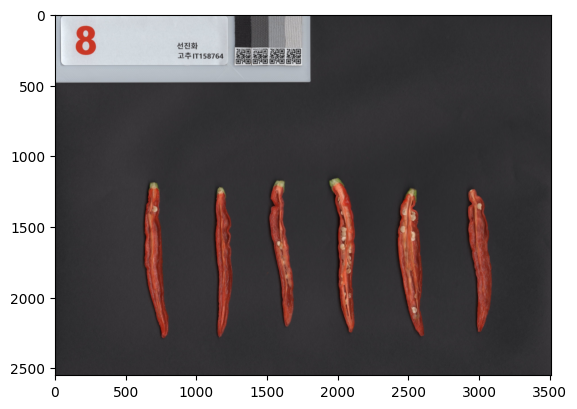

In [22]:
image = cv2.imread(image_paths[1])
image_RGB = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(image_RGB)
plt.show()

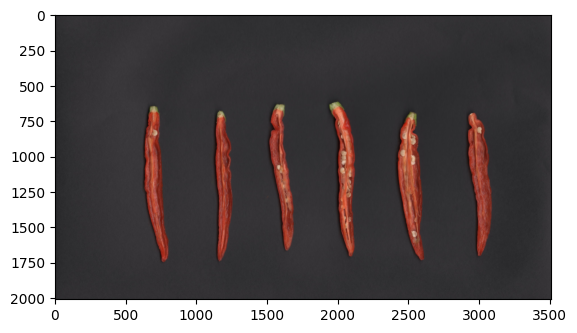

In [28]:
image_crop = image_RGB[540:, :, :]
plt.imshow(image_crop)
plt.show()

In [26]:
EP = 0.003

def hadle_segm(img, threshold=56):
    # print(type(img))
    img = img.copy()
    img = np.array(img)
    img = np.where(img >= threshold, 255, 0)

    return img
    
def get_mask(img,threshold = 16, use_closing = True, use_contour = True):
        img = img
        # cv2.imshow("", img)
        # cv2.imshow("2", img)
        
        img_red = np.array(img[:, :, 0])
        hist = cv2.calcHist([img_red], [0], None, [256], [0, 256])

        fruit_mask = hadle_segm(img_red, hist.argmax() + threshold)
        fruit_mask = fruit_mask.astype(np.uint8)
        # cv2.imshow("3", fruit_mask)

        if use_closing:
            kernel = np.ones((10, 10), np.uint8)
            fruit_mask = cv2.morphologyEx(fruit_mask, cv2.MORPH_CLOSE, kernel, iterations=1)
            fruit_mask = fruit_mask.astype(np.uint8)
        # cv2.imshow("4", fruit_mask)
        if use_contour:
            contours, hierarchy = cv2.findContours(fruit_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            contour_areas = [cv2.contourArea(cnt) for cnt in contours]
            max_area = max(contour_areas)
            fruit_mask = np.zeros_like(fruit_mask)
            contour_line = np.zeros_like(fruit_mask)
            for cnt in contours:
                area = cv2.contourArea(cnt)
                if area >= max_area:
                    cv2.drawContours(fruit_mask, [cnt], -1, (255, 255, 255), -1)
 
        return fruit_mask

def find_center(cnt):
    centroid_x = sum(x for x, y in cnt) / len(cnt)
    centroid_y = sum(y for x, y in cnt) / len(cnt)
    return centroid_x, centroid_y

def mask_img(img_path, ep= EP):
    img = cv2.imread(img_path)
    img_RGB = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.imshow(img_RGB)
    plt.show()
    img_red = img_RGB[540:, :, 0]
    plt.imshow(img_red)
    plt.show()
    img_mask = get_mask(img_RGB[540:, :, :], 22 , True, False)
    plt.imshow(img_mask)
    plt.show()
    
    contours, hierarchy = cv2.findContours(img_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contour_areas = [cv2.contourArea(cnt) for cnt in contours]
    max_area = max(contour_areas)
    fruit_mask = img_RGB[540:, :, :]
    masks = []
    for cnt in contours:
        area = cv2.contourArea(cnt)
        if area >= 10000:
            # print(cnt)
            # masks.append(cnt)
            cv2.drawContours(fruit_mask, [cnt], -1, (255, 255, 255), 2)
            length_L1 = cv2.arcLength(cnt, True)
            cnt = cv2.approxPolyDP(cnt, ep*length_L1, True)
            contour = [p[0].tolist() for p in cnt]
            contour_or = [[p[0],p[1]+540] for p in contour]
            masks.append(contour_or)
    
    plt.imshow(fruit_mask)
    plt.show()
    return masks

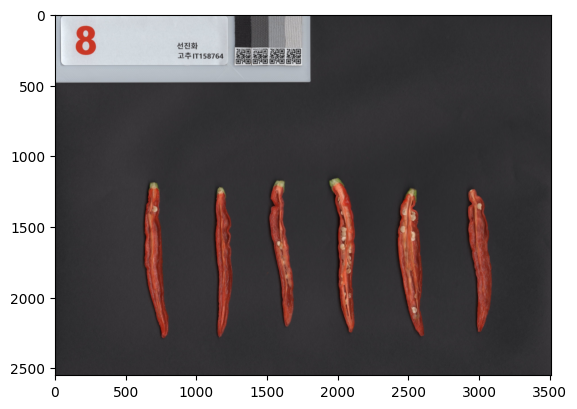

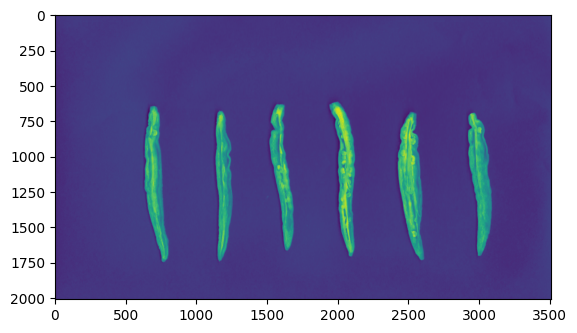

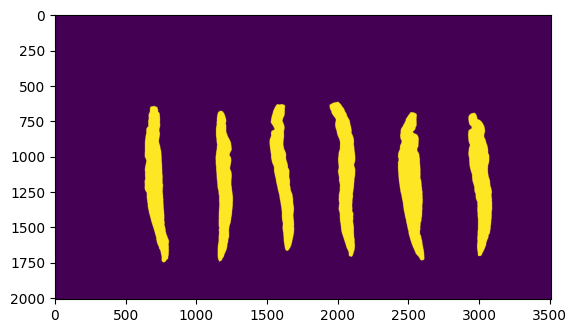

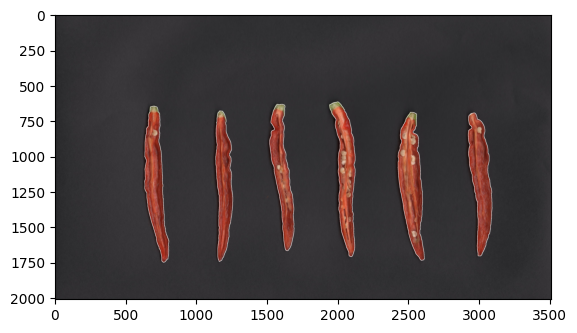

[[[2955, 1237],
  [2936, 1242],
  [2919, 1267],
  [2923, 1310],
  [2942, 1336],
  [2919, 1363],
  [2919, 1429],
  [2929, 1459],
  [2919, 1532],
  [2982, 1865],
  [2981, 2200],
  [2987, 2244],
  [3005, 2246],
  [3036, 2188],
  [3072, 2070],
  [3086, 1910],
  [3084, 1793],
  [3056, 1659],
  [3065, 1540],
  [3029, 1404],
  [3033, 1342],
  [3012, 1299],
  [2982, 1280],
  [2971, 1245]],
 [[2509, 1233],
  [2441, 1358],
  [2447, 1444],
  [2422, 1536],
  [2425, 1684],
  [2501, 2104],
  [2548, 2231],
  [2591, 2277],
  [2608, 2263],
  [2576, 2090],
  [2595, 1838],
  [2575, 1561],
  [2557, 1504],
  [2567, 1416],
  [2557, 1392],
  [2528, 1376],
  [2552, 1326],
  [2553, 1248]],
 [[1166, 1222],
  [1148, 1243],
  [1140, 1304],
  [1145, 1467],
  [1134, 1546],
  [1159, 1819],
  [1149, 2188],
  [1159, 2285],
  [1178, 2275],
  [1214, 2187],
  [1255, 1864],
  [1246, 1661],
  [1235, 1633],
  [1244, 1572],
  [1232, 1538],
  [1245, 1470],
  [1209, 1376],
  [1200, 1255],
  [1185, 1228]],
 [[693, 1189],
  [671

In [27]:
mask_img(image_paths[1])